# CDS 2413 — Deliverable 2: Machine Learning Model Report

## COVID-19 Recovery Dataset

###### Purpose: Preprocess the data, then build and compare regression, classification and clustering models for `days_to_recovery`, the dependent variable chosen in Deliverable 1.

### 1. Data collection

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, confusion_matrix,
                             accuracy_score, precision_score, recall_score, f1_score, silhouette_score,
                             adjusted_rand_score)
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
os.makedirs('figures', exist_ok=True)
RANDOM_STATE = 42

df = pd.read_csv('covid.csv')      # pd.read_excel('file.xlsx') would be used for an Excel file
print(df.shape)
df.head()

(70000, 28)


,patient_id,country,region/state,date_reported,age,gender,comorbidities,symptoms_1,symptoms_2,symptoms_3,severity,hospitalized,icu_admission,ventilator_support,vaccination_status,variant,treatment_given_1,treatment_given_2,days_to_recovery,recovered,death,date_of_recovery,date_of_death,tests_conducted,test_type,hospital_name,doctor_assigned,source_url
0,P000001,India,Sindh,44447,95,Female,Diabetes,Cough,NaN,NaN,Moderate,0,1,1,Full,Omicron,Antibiotics,NaN,18,0,1,44465.0,NaN,1,PCR,Aga Khan,Dr. Müller,https://who.int/sample
1,P000002,Pakistan,London,43930,92,Female,Diabetes,Loss of Smell,Fatigue,Fatigue,Moderate,0,1,1,NaN,Omicron,Remdesivir,Antibiotics,9,0,1,43939.0,NaN,3,PCR,Jinnah Hospital,Dr. Silva,https://who.int/sample
2,P000003,Germany,Berlin,44718,78,Female,NaN,Headache,Loss of Smell,Loss of Smell,Critical,0,0,0,NaN,Omicron,Antibiotics,Oxygen,27,0,1,44745.0,NaN,2,Antigen,Jinnah Hospital,Dr. Smith,https://who.int/sample
3,P000004,India,Cape Town,44107,36,Female,Cancer,Cough,Fatigue,Fatigue,Mild,1,1,1,Full,Omicron,Antibiotics,NaN,25,1,1,44132.0,NaN,2,PCR,Mayo Clinic,Dr. Silva,https://who.int/sample
4,P000005,UK,Berlin,44083,99,Male,Diabetes,Fatigue,NaN,NaN,Mild,1,1,1,NaN,Omicron,Oxygen,Steroids,17,0,0,NaN,44123.0,4,PCR,AIIMS,Dr. Smith,https://who.int/sample


### 2. Data cleaning

###### 2.1 Remove conflicting records (same rule as Deliverable 1) and check duplicates

In [2]:
df_clean = df[~((df['recovered'] == 1) & (df['death'] == 1))].copy()
print('Original rows:', len(df))
print('Rows after removing recovered=1 & death=1 conflicts:', len(df_clean))
print('Duplicate rows:', df_clean.duplicated().sum())
print('Duplicate patient_id values:', df_clean['patient_id'].duplicated().sum())

Original rows: 70000
Rows after removing recovered=1 & death=1 conflicts: 57514
Duplicate rows: 0
Duplicate patient_id values: 0


###### 2.2 Hospitalisation flags are fully determined by `severity`, so they add no information

In [3]:
print(pd.crosstab(df_clean['severity'],
                  [df_clean['hospitalized'], df_clean['icu_admission'], df_clean['ventilator_support']]))

hospitalized           0                   1
icu_admission          0            1      1
ventilator_support     0     1      1      1
severity                                    
Critical            3229     0      0      0
Mild                   0     0      0  34033
Moderate               0     0  14266      0
Severe                 0  5986      0      0


###### 2.3 Leakage check: the recovery date minus the report date reproduces the target

In [4]:
gap = df_clean['date_of_recovery'] - df_clean['date_reported']
print('Rows where date_of_recovery - date_reported == days_to_recovery:',
      round((gap == df_clean['days_to_recovery']).mean() * 100, 1), '%')

Rows where date_of_recovery - date_reported == days_to_recovery: 71.2 %


###### 2.4 Drop columns that are identifiers, constant, redundant, leaking the target, or mostly empty

In [5]:
drop_cols = ['patient_id', 'source_url', 'hospital_name', 'doctor_assigned',      # identifiers / constant
             'country', 'region/state',                                           # region does not match country
             'date_reported', 'date_of_recovery', 'date_of_death',                # dates (leakage)
             'recovered', 'death',                                                # outcomes, not predictors
             'hospitalized', 'icu_admission', 'ventilator_support',               # duplicates of severity
             'symptoms_2', 'symptoms_3', 'treatment_given_2']                     # ~40% missing
print('source_url unique values:', df_clean['source_url'].nunique())
print(pd.crosstab(df_clean['country'], df_clean['region/state']).iloc[:4, :6])
data = df_clean.drop(columns=drop_cols)
print('Remaining columns:', list(data.columns))

source_url unique values: 1
region/state  Beijing  Berlin  California  Cape Town  London  Punjab
country                                                             
Brazil            892     934         851        915     896     939
China             881     869         896        875     868     905
Germany           899     896         938        885     930     967
India             901     926         923        838     909     888
Remaining columns: ['age', 'gender', 'comorbidities', 'symptoms_1', 'severity', 'vaccination_status', 'variant', 'treatment_given_1', 'days_to_recovery', 'tests_conducted', 'test_type']


###### 2.5 Missing values

In [6]:
print(data.isnull().sum())
data['comorbidities'] = data['comorbidities'].fillna('None')          # no comorbidity recorded
data['vaccination_status'] = data['vaccination_status'].fillna('Unknown')
print('Missing values after treatment:', data.isnull().sum().sum())

age                       0
gender                    0
comorbidities          9490
symptoms_1                0
severity                  0
vaccination_status    23337
variant                   0
treatment_given_1         0
days_to_recovery          0
tests_conducted           0
test_type                 0
dtype: int64
Missing values after treatment: 0


###### 2.6 Outlier detection with the IQR rule

In [7]:
def iqr_outliers(frame, col):
    q1, q3 = frame[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return frame[(frame[col] < low) | (frame[col] > high)], low, high

outlier_idx = set()
for col in ['age', 'tests_conducted', 'days_to_recovery']:
    out, low, high = iqr_outliers(data, col)
    outlier_idx |= set(out.index)
    print(f'{col:18s} bounds [{low:.1f}, {high:.1f}]  outliers: {len(out)}')
data = data.drop(index=list(outlier_idx))
print('Rows after outlier removal:', len(data))
data[['age', 'tests_conducted', 'days_to_recovery']].describe().round(2)

age                bounds [-49.0, 151.0]  outliers: 0
tests_conducted    bounds [-1.0, 7.0]  outliers: 0
days_to_recovery   bounds [-8.5, 43.5]  outliers: 0
Rows after outlier removal: 57514


,age,tests_conducted,days_to_recovery
count,57514.00,57514.00,57514.00
mean,51.03,3.01,17.55
std,28.98,1.41,7.52
min,1.00,1.00,5.00
25%,26.00,2.00,11.00
50%,51.00,3.00,18.00
75%,76.00,4.00,24.00
max,100.00,5.00,30.00


### 3. Treating the categorical variables

In [8]:
for col in data.select_dtypes(exclude='number').columns:
    print(f'{col:20s}', data[col].nunique(), 'levels:', sorted(data[col].unique())[:7])

gender               2 levels: ['Female', 'Male']
comorbidities        6 levels: ['Asthma', 'Cancer', 'Diabetes', 'Heart Disease', 'Hypertension', 'None']
symptoms_1           6 levels: ['Cough', 'Fatigue', 'Fever', 'Headache', 'Loss of Smell', 'Sore Throat']
severity             4 levels: ['Critical', 'Mild', 'Moderate', 'Severe']
vaccination_status   4 levels: ['Booster', 'Full', 'Partial', 'Unknown']
variant              3 levels: ['Alpha', 'Delta', 'Omicron']
treatment_given_1    5 levels: ['Antibiotics', 'Oxygen', 'Paracetamol', 'Remdesivir', 'Steroids']
test_type            2 levels: ['Antigen', 'PCR']


In [9]:
encoded = data.copy()
# Ordinal: severity has a natural order
encoded['severity'] = encoded['severity'].map({'Mild': 0, 'Moderate': 1, 'Severe': 2, 'Critical': 3})
# Binary: label-encode as 0/1
encoded['gender'] = (encoded['gender'] == 'Male').astype(int)
encoded['test_type'] = (encoded['test_type'] == 'PCR').astype(int)
# Nominal: one-hot encode, drop the first level to avoid the dummy-variable trap
nominal = ['comorbidities', 'vaccination_status', 'variant', 'treatment_given_1', 'symptoms_1']
encoded = pd.get_dummies(encoded, columns=nominal, drop_first=True, dtype=int)

X = encoded.drop(columns='days_to_recovery')
y = encoded['days_to_recovery']
print('X shape:', X.shape)
print(list(X.columns))

X shape: (57514, 24)
['age', 'gender', 'severity', 'tests_conducted', 'test_type', 'comorbidities_Cancer', 'comorbidities_Diabetes', 'comorbidities_Heart Disease', 'comorbidities_Hypertension', 'comorbidities_None', 'vaccination_status_Full', 'vaccination_status_Partial', 'vaccination_status_Unknown', 'variant_Delta', 'variant_Omicron', 'treatment_given_1_Oxygen', 'treatment_given_1_Paracetamol', 'treatment_given_1_Remdesivir', 'treatment_given_1_Steroids', 'symptoms_1_Fatigue', 'symptoms_1_Fever', 'symptoms_1_Headache', 'symptoms_1_Loss of Smell', 'symptoms_1_Sore Throat']


### 4. Splitting the dataset (80% train / 20% test)

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' Test:', X_test.shape)
print('Train mean days:', round(y_train.mean(), 3), ' Test mean days:', round(y_test.mean(), 3))

Train: (46011, 24)  Test: (11503, 24)
Train mean days: 17.545  Test mean days: 17.56


### 5. Feature scaling (StandardScaler, fitted on the training set only)

In [11]:
scaler = StandardScaler()
X_train_s = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_s = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print(X_train_s[['age', 'tests_conducted', 'severity']].describe().loc[['mean', 'std']].round(3))

      age  tests_conducted  severity
mean -0.0             -0.0      -0.0
std   1.0              1.0       1.0


## Regression

###### 6.1 Simple linear regression: days_to_recovery ~ age

days_to_recovery = 17.5811 + (-0.000700 x age)
Test R2: -3e-05  MSE: 56.017


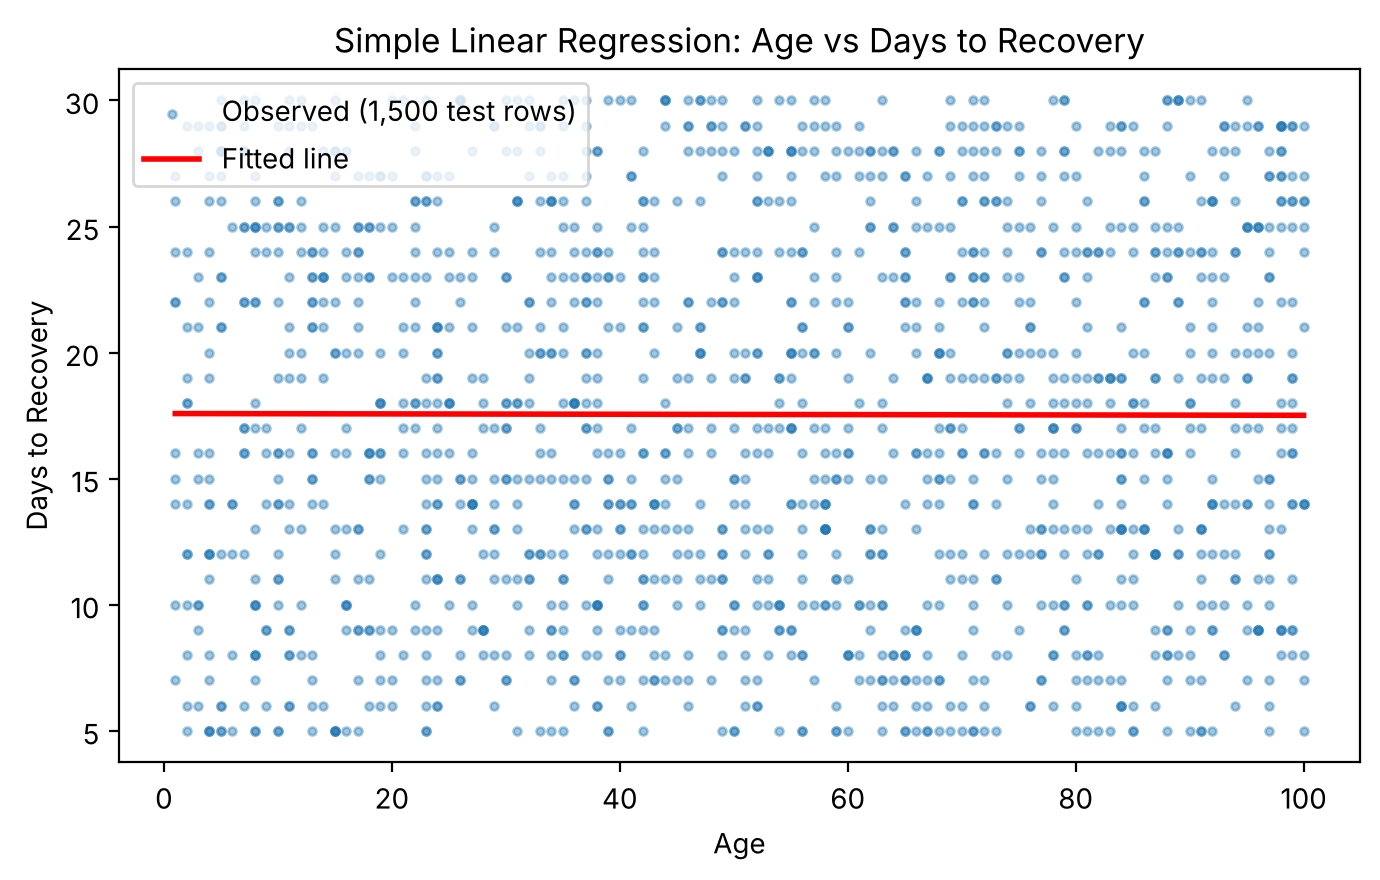

In [12]:
slr = LinearRegression().fit(X_train[['age']], y_train)
slr_pred = slr.predict(X_test[['age']])
print(f'days_to_recovery = {slr.intercept_:.4f} + ({slr.coef_[0]:.6f} x age)')
print('Test R2:', round(r2_score(y_test, slr_pred), 5), ' MSE:', round(mean_squared_error(y_test, slr_pred), 3))

plt.figure(figsize=(7, 4.5))
sample_idx = X_test.sample(1500, random_state=RANDOM_STATE).index
plt.scatter(X_test.loc[sample_idx, 'age'], y_test.loc[sample_idx], s=8, alpha=0.4, label='Observed (1,500 test rows)')
ages = np.linspace(X['age'].min(), X['age'].max(), 100).reshape(-1, 1)
plt.plot(ages, slr.predict(pd.DataFrame(ages, columns=['age'])), color='red', lw=2, label='Fitted line')
plt.xlabel('Age'); plt.ylabel('Days to Recovery'); plt.title('Simple Linear Regression: Age vs Days to Recovery')
plt.legend(); plt.tight_layout(); plt.savefig('figures/reg_simple.png', dpi=150); plt.show()

###### 6.2 Tune the regularisation strength of Ridge, Lasso and Elastic Net with 5-fold cross-validation

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grids = {
    'Ridge': (Ridge(), {'alpha': [0.01, 0.1, 1, 10, 100, 1000]}),
    'Lasso': (Lasso(max_iter=10000), {'alpha': [0.0005, 0.001, 0.01, 0.05, 0.1, 0.5]}),
    'Elastic Net': (ElasticNet(max_iter=10000), {'alpha': [0.001, 0.01, 0.05, 0.1, 0.5], 'l1_ratio': [0.2, 0.5, 0.8]}),
}
best_params = {}
for name, (model, grid) in grids.items():
    gs = GridSearchCV(model, grid, cv=cv, scoring='r2').fit(X_train_s, y_train)
    best_params[name] = gs.best_params_
    print(f'{name:12s} best params {gs.best_params_}  CV R2 = {gs.best_score_:.5f}')

Ridge        best params {'alpha': 1000}  CV R2 = -0.00104


Lasso        best params {'alpha': 0.5}  CV R2 = -0.00015


Elastic Net  best params {'alpha': 0.5, 'l1_ratio': 0.5}  CV R2 = -0.00015


###### 6.3 Fit all regression models and compare on the test set

In [14]:
reg_models = {
    'Baseline (predict mean)': DummyRegressor(strategy='mean'),
    'Multiple Linear Regression': LinearRegression(),
    'Polynomial Regression (deg 2)': make_pipeline(PolynomialFeatures(degree=2, include_bias=False), LinearRegression()),
    'Ridge Regression': Ridge(**best_params['Ridge']),
    'Lasso Regression': Lasso(max_iter=10000, **best_params['Lasso']),
    'Elastic Net Regression': ElasticNet(max_iter=10000, **best_params['Elastic Net']),
    'Decision Tree Regressor': DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=RANDOM_STATE),
    'Random Forest Regressor': RandomForestRegressor(n_estimators=150, min_samples_leaf=30, n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting Regressor': HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE),
}
reg_rows, reg_preds = [], {}
for name, model in reg_models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    reg_preds[name] = pred
    cv_r2 = cross_val_score(model, X_train_s, y_train, cv=cv, scoring='r2').mean() if 'Polynomial' not in name else np.nan
    reg_rows.append({'Model': name,
                     'MSE': mean_squared_error(y_test, pred),
                     'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
                     'MAE': mean_absolute_error(y_test, pred),
                     'R2 (test)': r2_score(y_test, pred),
                     'R2 (5-fold CV)': cv_r2})
poly_cv = cross_val_score(reg_models['Polynomial Regression (deg 2)'], X_train_s, y_train, cv=cv, scoring='r2').mean()
reg_results = pd.DataFrame(reg_rows)
reg_results.loc[reg_results['Model'].str.startswith('Polynomial'), 'R2 (5-fold CV)'] = poly_cv
reg_results = reg_results.round(5)
reg_results

,Model,MSE,RMSE,MAE,R2 (test),R2 (5-fold CV)
0,Baseline (predict mean),56.01539,7.48434,6.48025,-0.00000,-0.00015
1,Multiple Linear Regression,56.04193,7.48612,6.48106,-0.00048,-0.00111
2,Polynomial Regression (deg 2),56.37351,7.50823,6.49331,-0.00640,-0.00907
3,Ridge Regression,56.04050,7.48602,6.48102,-0.00045,-0.00104
4,Lasso Regression,56.01539,7.48434,6.48025,-0.00000,-0.00015
5,Elastic Net Regression,56.01539,7.48434,6.48025,-0.00000,-0.00015
6,Decision Tree Regressor,56.12801,7.49186,6.48633,-0.00201,-0.00407
7,Random Forest Regressor,56.39882,7.50992,6.49482,-0.00685,-0.00802
8,Gradient Boosting Regressor,56.01102,7.48405,6.48054,0.00007,-0.00102


In [15]:
candidates = reg_results[reg_results['Model'] != 'Baseline (predict mean)']
# Rank on 5-fold CV R2 (averaged over 5 folds, so less sensitive to one lucky split); ties go to the simpler model
best_reg_name = candidates.sort_values(['R2 (5-fold CV)', 'R2 (test)'], ascending=False).iloc[0]['Model']
best_reg = reg_models[best_reg_name]
print('Best-fit regression model (highest 5-fold CV R2):', best_reg_name)
print('Highest single test-set R2:', candidates.loc[candidates['R2 (test)'].idxmax(), 'Model'])
print(candidates.set_index('Model').loc[best_reg_name])

Best-fit regression model (highest 5-fold CV R2): Lasso Regression
Highest single test-set R2: Gradient Boosting Regressor
MSE               56.01539
RMSE               7.48434
MAE                6.48025
R2 (test)         -0.00000
R2 (5-fold CV)    -0.00015
Name: Lasso Regression, dtype: float64


###### 6.4 Regression equations

In [16]:
def equation(intercept, coefs, names, digits=4):
    terms = [f'({c:+.{digits}f} x {n})' for c, n in zip(coefs, names) if abs(c) > 1e-12]
    return f'days_to_recovery = {intercept:.{digits}f} ' + (' + '.join(terms) if terms else '(all coefficients shrunk to 0)')

for name in ['Multiple Linear Regression', 'Ridge Regression', 'Lasso Regression', 'Elastic Net Regression']:
    m = reg_models[name]
    print(f'--- {name} (standardised features) ---')
    print(equation(m.intercept_, m.coef_, X.columns))
    print('non-zero coefficients:', int(np.sum(np.abs(m.coef_) > 1e-12)), 'of', len(m.coef_), '\n')

poly = reg_models['Polynomial Regression (deg 2)']
print('Polynomial regression: intercept', round(poly[-1].intercept_, 4), 'with', len(poly[-1].coef_), 'terms')

--- Multiple Linear Regression (standardised features) ---
days_to_recovery = 17.5454 (-0.0206 x age) + (+0.0510 x gender) + (+0.0585 x severity) + (-0.0645 x tests_conducted) + (+0.0379 x test_type) + (+0.0111 x comorbidities_Cancer) + (-0.0063 x comorbidities_Diabetes) + (-0.0728 x comorbidities_Heart Disease) + (-0.0467 x comorbidities_Hypertension) + (-0.0178 x comorbidities_None) + (-0.0393 x vaccination_status_Full) + (+0.0097 x vaccination_status_Partial) + (-0.0213 x vaccination_status_Unknown) + (-0.0168 x variant_Delta) + (+0.0016 x variant_Omicron) + (+0.0004 x treatment_given_1_Oxygen) + (+0.0174 x treatment_given_1_Paracetamol) + (-0.0347 x treatment_given_1_Remdesivir) + (-0.0374 x treatment_given_1_Steroids) + (-0.0202 x symptoms_1_Fatigue) + (+0.0207 x symptoms_1_Fever) + (-0.0614 x symptoms_1_Headache) + (-0.0323 x symptoms_1_Loss of Smell) + (-0.0222 x symptoms_1_Sore Throat)
non-zero coefficients: 24 of 24 

--- Ridge Regression (standardised features) ---
days_to_re

###### Equation in original units (unscaled MLR) for the hand calculation

In [17]:
mlr_raw = LinearRegression().fit(X_train, y_train)
coef_table = pd.DataFrame({'feature': X.columns, 'coefficient': mlr_raw.coef_}).round(4)
print('Intercept:', round(mlr_raw.intercept_, 4))
print(coef_table.to_string(index=False))

Intercept: 17.7715
                      feature  coefficient
                          age      -0.0007
                       gender       0.1020
                     severity       0.0662
              tests_conducted      -0.0456
                    test_type       0.0758
         comorbidities_Cancer       0.0298
       comorbidities_Diabetes      -0.0170
  comorbidities_Heart Disease      -0.1951
   comorbidities_Hypertension      -0.1251
           comorbidities_None      -0.0478
      vaccination_status_Full      -0.0917
   vaccination_status_Partial       0.0240
   vaccination_status_Unknown      -0.0433
                variant_Delta      -0.0368
              variant_Omicron       0.0032
     treatment_given_1_Oxygen       0.0011
treatment_given_1_Paracetamol       0.0437
 treatment_given_1_Remdesivir      -0.0867
   treatment_given_1_Steroids      -0.0933
           symptoms_1_Fatigue      -0.0543
             symptoms_1_Fever       0.0557
          symptoms_1_Headache      

In [18]:
five = data.sample(5, random_state=7)
five_X = X.loc[five.index]
hand = pd.DataFrame({
    'age': five['age'], 'severity': five['severity'], 'vaccination': five['vaccination_status'],
    'tests': five['tests_conducted'],
    'Observed days': five['days_to_recovery'],
    f'{best_reg_name} prediction': best_reg.predict(scaler.transform(five_X)).round(2),
    'MLR prediction': mlr_raw.predict(five_X).round(2)})
hand

,age,severity,vaccination,tests,Observed days,Lasso Regression prediction,MLR prediction
52646,76,Mild,Partial,4,28,17.55,17.56
22970,66,Severe,Full,1,30,17.55,17.70
60733,35,Mild,Full,2,19,17.55,17.74
26671,70,Mild,Unknown,4,13,17.55,17.48
24344,13,Mild,Booster,5,19,17.55,17.41


###### 6.5 Observed vs predicted for the best-fit model

   Observed  Predicted  Error
0        12      17.55  -5.55
1         6      17.55 -11.55
2        29      17.55  11.45
3        11      17.55  -6.55
4        17      17.55  -0.55
5        11      17.55  -6.55
6        10      17.55  -7.55
7         8      17.55  -9.55
8        11      17.55  -6.55
9        19      17.55   1.45


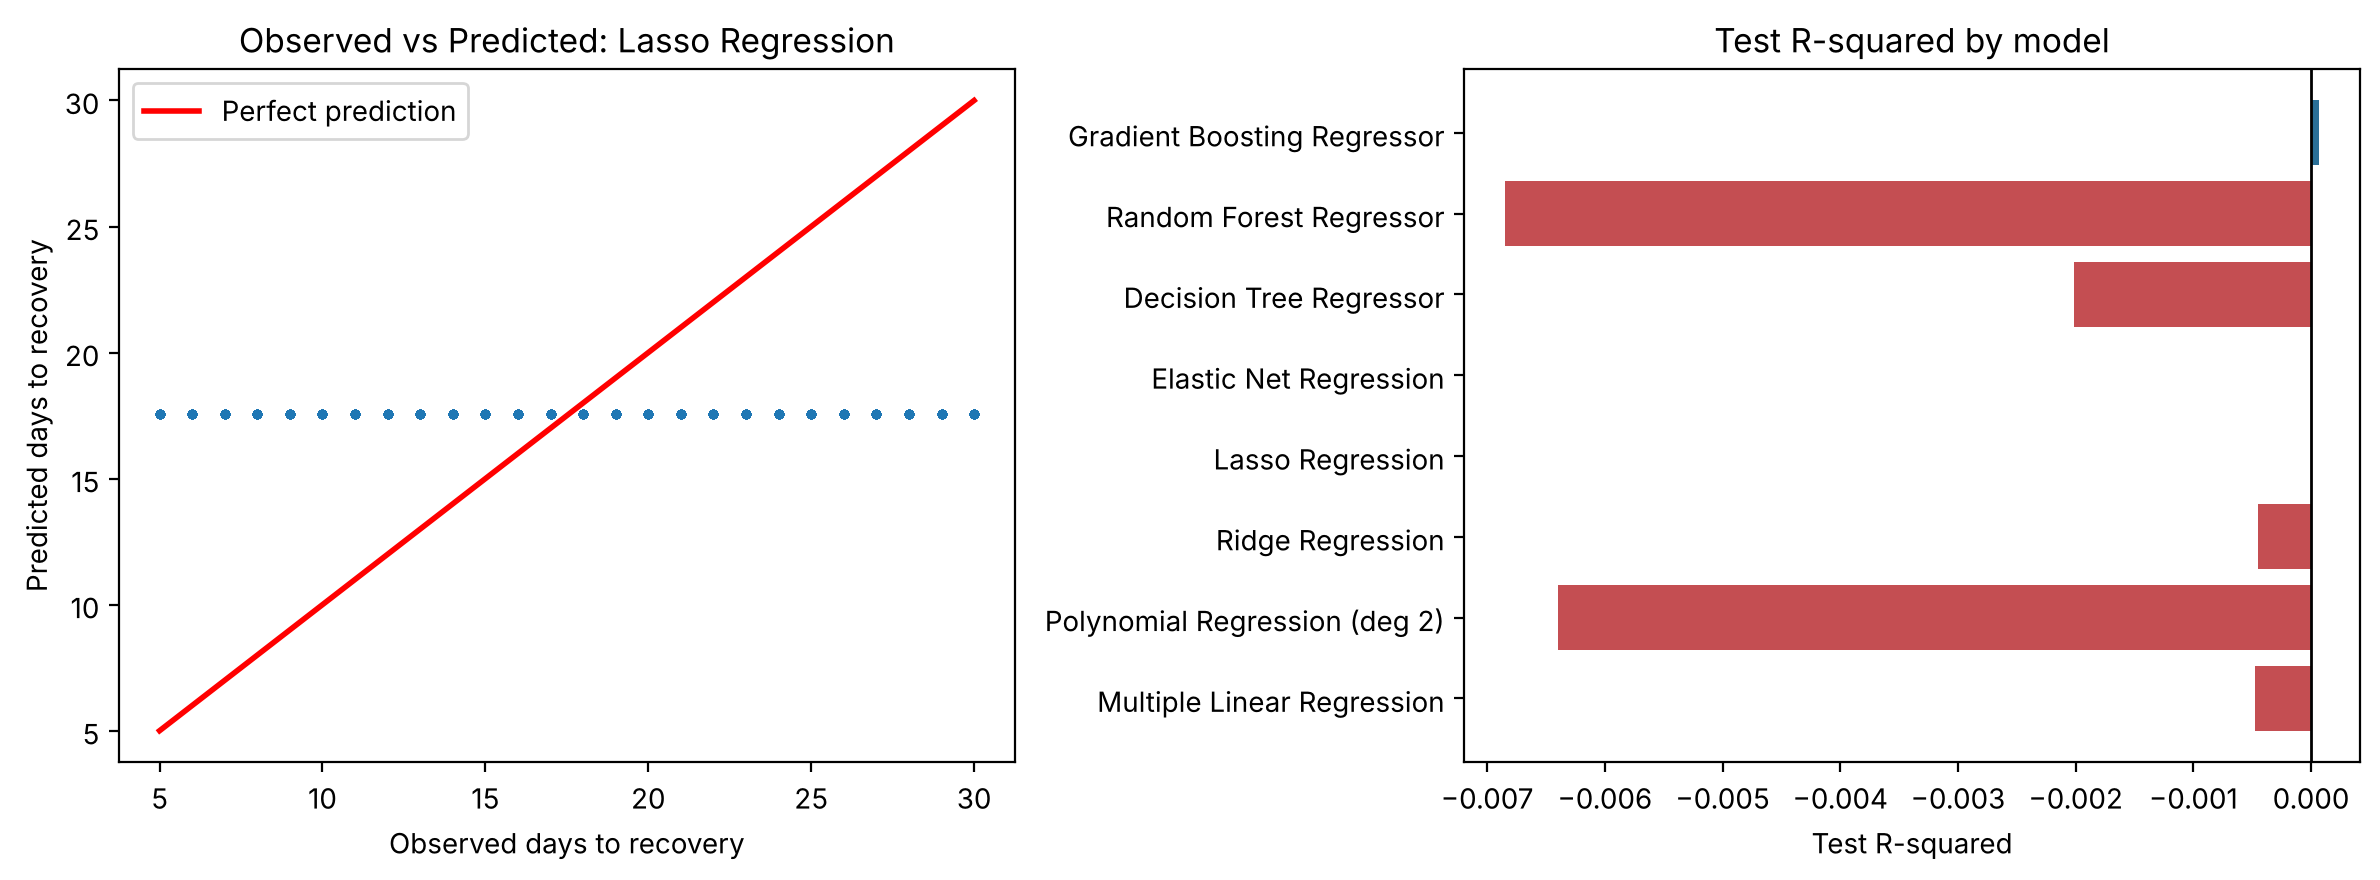

In [19]:
best_pred = reg_preds[best_reg_name]
comparison = pd.DataFrame({'Observed': y_test.values[:10], 'Predicted': best_pred[:10].round(2)})
comparison['Error'] = (comparison['Observed'] - comparison['Predicted']).round(2)
print(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(y_test, best_pred, s=6, alpha=0.3)
axes[0].plot([5, 30], [5, 30], color='red', lw=2, label='Perfect prediction')
axes[0].set_xlabel('Observed days to recovery'); axes[0].set_ylabel('Predicted days to recovery')
axes[0].set_title(f'Observed vs Predicted: {best_reg_name}'); axes[0].legend()
r2_plot = reg_results.set_index('Model')['R2 (test)'].drop('Baseline (predict mean)')
axes[1].barh(r2_plot.index, r2_plot.values, color=['#2a6f97' if v >= 0 else '#c44e52' for v in r2_plot.values])
axes[1].axvline(0, color='black', lw=1)
axes[1].set_xlabel('Test R-squared'); axes[1].set_title('Test R-squared by model')
plt.tight_layout(); plt.savefig('figures/reg_observed_vs_pred.png', dpi=150); plt.show()

## Classification

###### 7.1 Categorise the target: Prolonged (> 18 days, the median) vs Short (<= 18 days)

In [20]:
median_days = data['days_to_recovery'].median()
y_cls = (y > median_days).astype(int)        # 1 = Prolonged recovery, 0 = Short recovery
labels = ['Short (<=18 days)', 'Prolonged (>18 days)']
print('Median days_to_recovery:', median_days)
print(y_cls.map({0: labels[0], 1: labels[1]}).value_counts())
print((y_cls.value_counts(normalize=True) * 100).round(2))

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_cls, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls)
cls_scaler = StandardScaler().fit(Xc_train)
Xc_train_s = cls_scaler.transform(Xc_train)
Xc_test_s = cls_scaler.transform(Xc_test)

Median days_to_recovery: 18.0
days_to_recovery
Short (<=18 days)       30818
Prolonged (>18 days)    26696
Name: count, dtype: int64
days_to_recovery
0    53.58
1    46.42
Name: proportion, dtype: float64


###### 7.2 Tune KNN and Decision Tree

In [21]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
knn_gs = GridSearchCV(KNeighborsClassifier(), {'n_neighbors': [5, 15, 31, 51, 101]}, cv=skf, scoring='accuracy', n_jobs=-1).fit(Xc_train_s, yc_train)
dt_gs = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {'max_depth': [3, 5, 8, 12, None], 'min_samples_leaf': [1, 50, 200]},
                     cv=skf, scoring='accuracy', n_jobs=-1).fit(Xc_train_s, yc_train)
print('KNN best:', knn_gs.best_params_, round(knn_gs.best_score_, 4))
print('Decision Tree best:', dt_gs.best_params_, round(dt_gs.best_score_, 4))

KNN best: {'n_neighbors': 101} 0.5202
Decision Tree best: {'max_depth': 3, 'min_samples_leaf': 1} 0.5331


###### 7.3 Train, evaluate and compare classifiers (SVM is trained on a 10,000-row stratified subsample because its cost grows with the square of the row count)

In [22]:
svm_idx = pd.Series(yc_train.values).groupby(yc_train.values, group_keys=False).apply(
    lambda s: s.sample(5000, random_state=RANDOM_STATE)).index.values

classifiers = {
    'Baseline (majority class)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'K-Nearest Neighbors': KNeighborsClassifier(**knn_gs.best_params_),
    'Naive Bayes': GaussianNB(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE, **dt_gs.best_params_),
    'Support Vector Machine': SVC(kernel='rbf', C=1.0, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, min_samples_leaf=20, n_jobs=-1, random_state=RANDOM_STATE),
}
cls_rows, cls_fitted = [], {}
for name, clf in classifiers.items():
    Xtr, ytr = (Xc_train_s[svm_idx], yc_train.values[svm_idx]) if name == 'Support Vector Machine' else (Xc_train_s, yc_train)
    clf.fit(Xtr, ytr)
    pred = clf.predict(Xc_test_s)
    cm = confusion_matrix(yc_test, pred)
    cv_acc = cross_val_score(clf, Xtr, ytr, cv=skf, scoring='accuracy', n_jobs=-1).mean()
    cls_fitted[name] = clf
    cls_rows.append({'Model': name, 'Confusion Matrix': cm.tolist(), 'Errors (FP + FN)': int(cm[0, 1] + cm[1, 0]),
                     'Accuracy': accuracy_score(yc_test, pred),
                     'Precision': precision_score(yc_test, pred, zero_division=0),
                     'Recall': recall_score(yc_test, pred, zero_division=0),
                     'Macro F1': f1_score(yc_test, pred, average='macro', zero_division=0),
                     'F1-score': f1_score(yc_test, pred, zero_division=0),
                     'CV Accuracy': cv_acc})
cls_results = pd.DataFrame(cls_rows).round(4)
cls_results

,Model,Confusion Matrix,Errors (FP + FN),Accuracy,Precision,Recall,Macro F1,F1-score,CV Accuracy
0,Baseline (majority class),"[[6164, 0], [5339, 0]]",5339,0.5359,0.0000,0.0000,0.3489,0.0000,0.5358
1,Logistic Regression,"[[6164, 0], [5339, 0]]",5339,0.5359,0.0000,0.0000,0.3489,0.0000,0.5359
2,K-Nearest Neighbors,"[[4684, 1480], [4129, 1210]]",5609,0.5124,0.4498,0.2266,0.4634,0.3014,0.5202
3,Naive Bayes,"[[5788, 376], [5038, 301]]",5414,0.5293,0.4446,0.0564,0.3907,0.1001,0.5293
4,Decision Tree,"[[6164, 0], [5339, 0]]",5339,0.5359,0.0000,0.0000,0.3489,0.0000,0.5331
5,Support Vector Machine,"[[3049, 3115], [2652, 2687]]",5767,0.4987,0.4631,0.5033,0.4982,0.4824,0.4938
6,Random Forest,"[[5638, 526], [4930, 409]]",5456,0.5257,0.4374,0.0766,0.4021,0.1304,0.5312


Highest accuracy: Logistic Regression (predicts only one class: identical to the baseline)
Best-fit classifier (highest macro F1): Support Vector Machine
Confusion Matrix    [[3049, 3115], [2652, 2687]]
Errors (FP + FN)                            5767
Accuracy                                  0.4987
Precision                                 0.4631
Recall                                    0.5033
Macro F1                                  0.4982
F1-score                                  0.4824
CV Accuracy                               0.4938
Name: Support Vector Machine, dtype: object


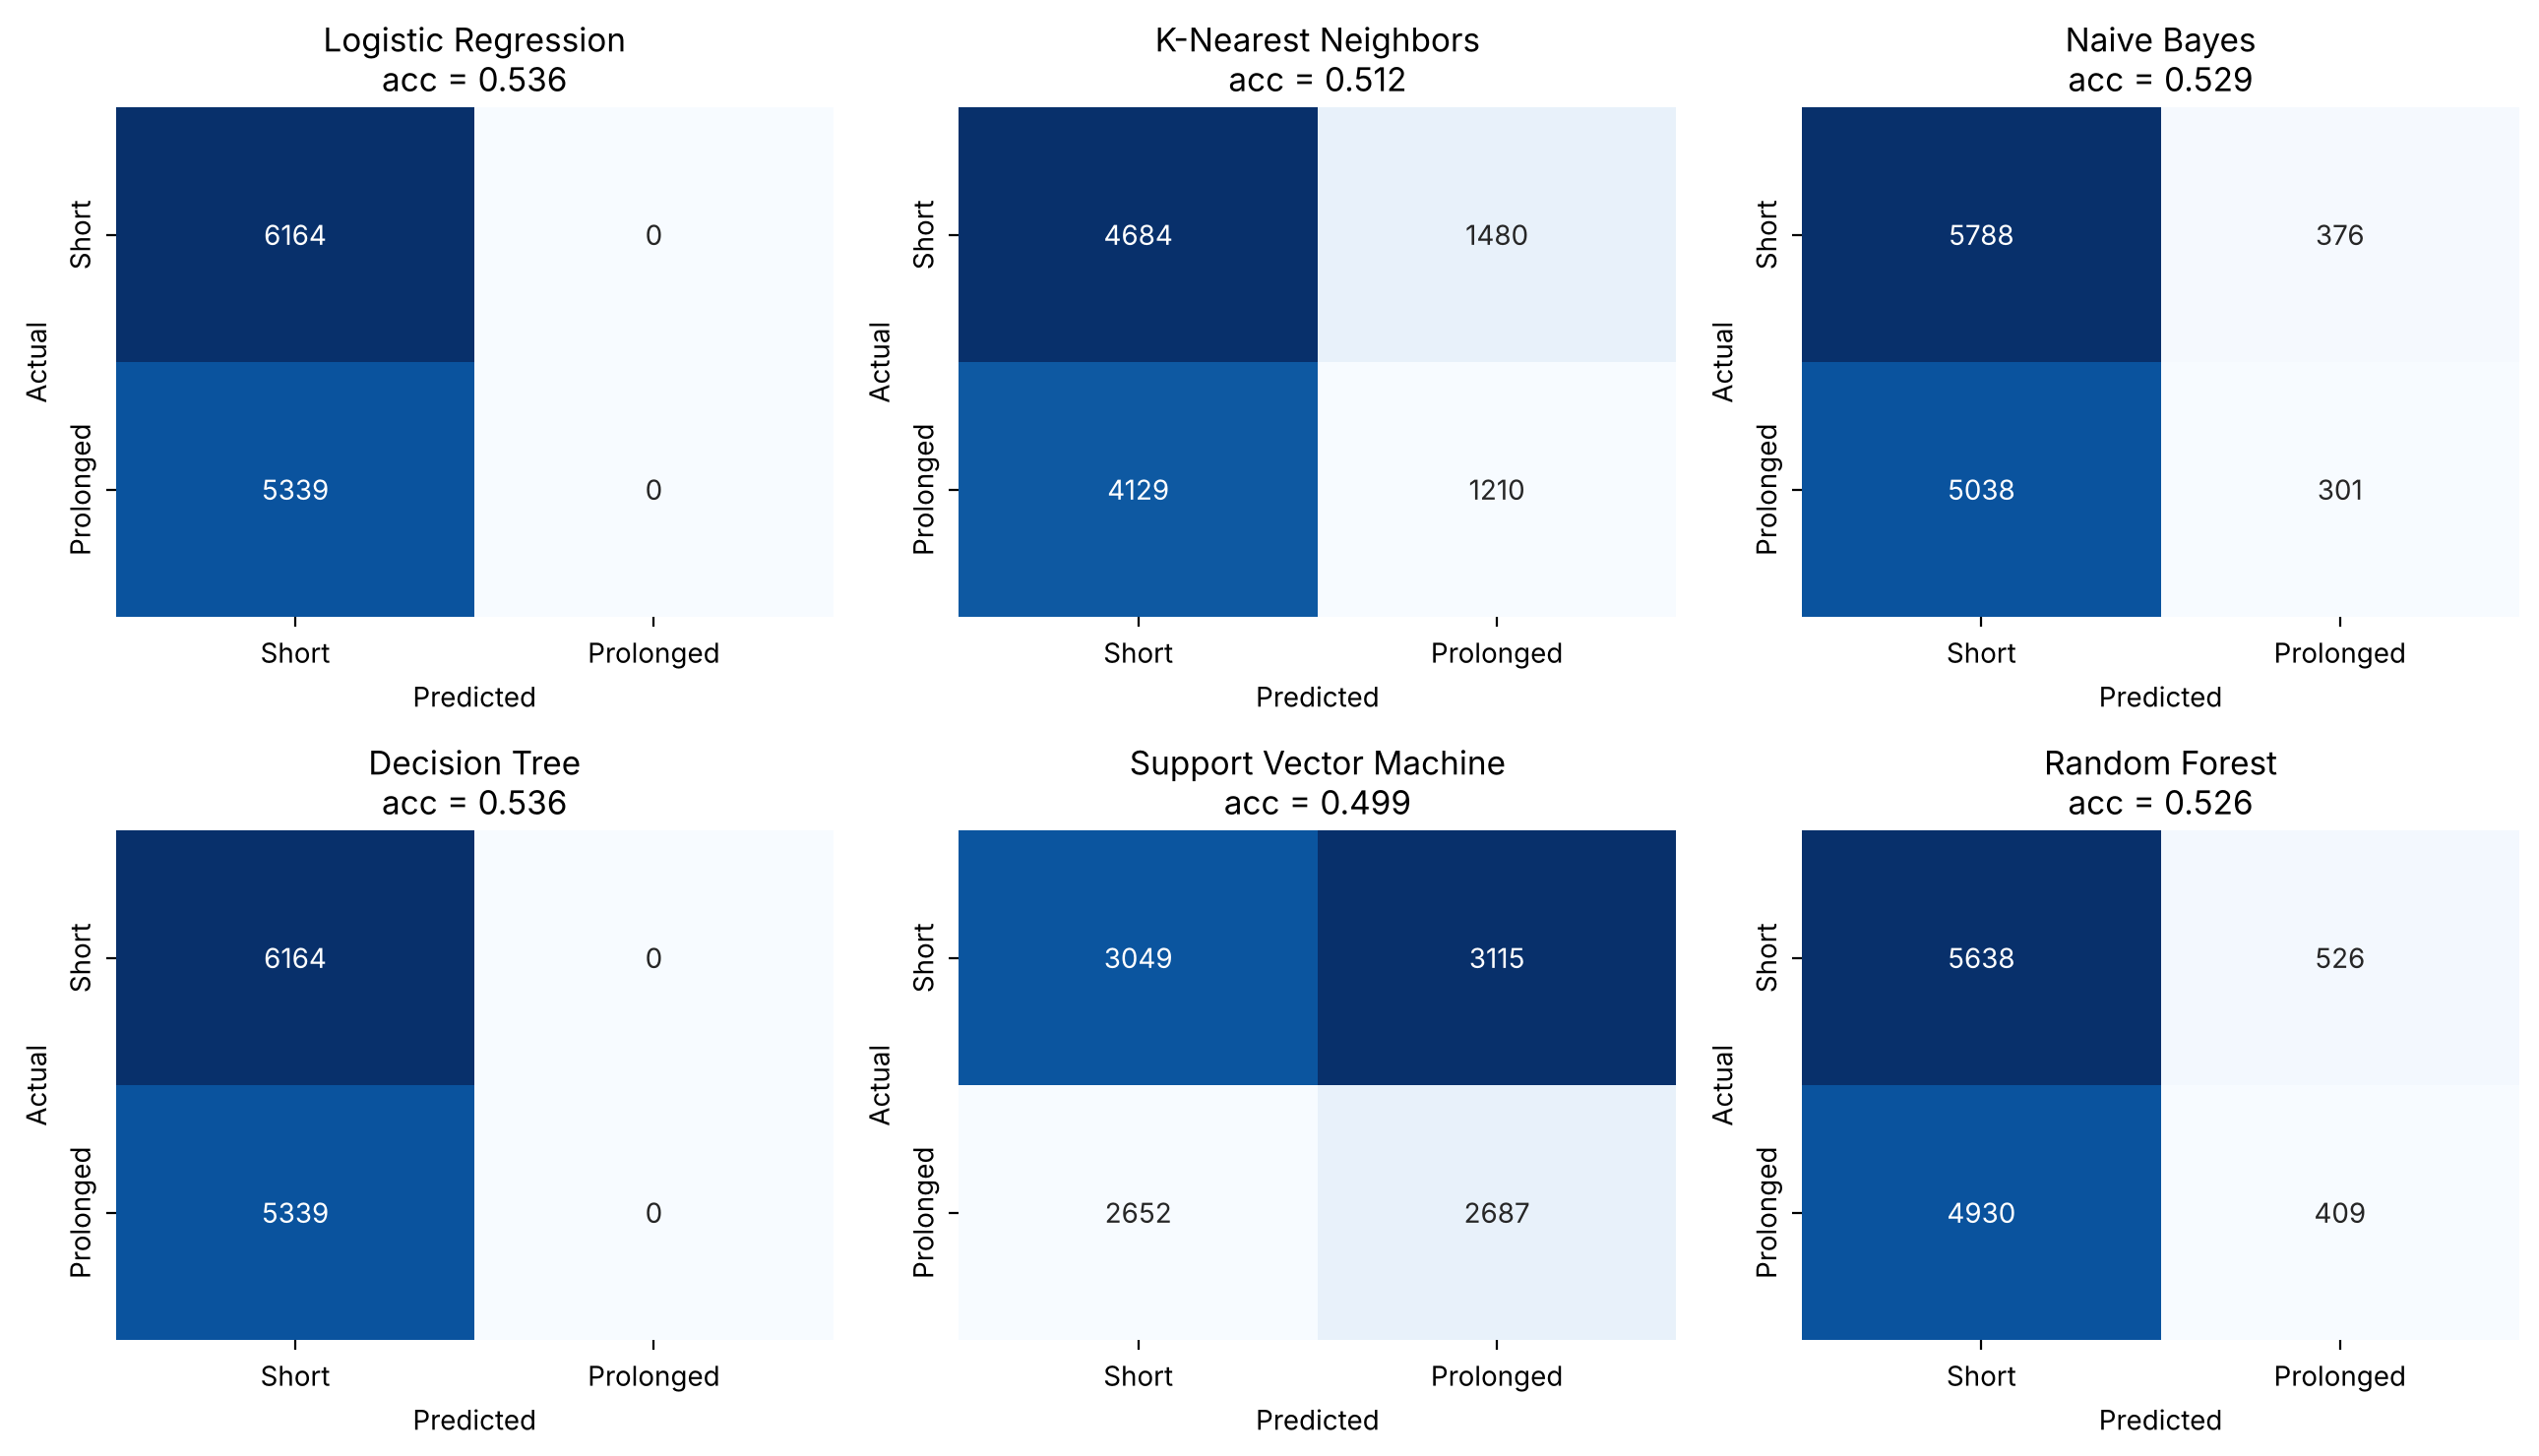

In [23]:
cand = cls_results[cls_results['Model'] != 'Baseline (majority class)']
# Accuracy alone rewards models that predict only the majority class, so rank on macro F1 (both classes weighted equally)
best_cls_name = cand.loc[cand['Macro F1'].idxmax(), 'Model']
print('Highest accuracy:', cand.loc[cand['Accuracy'].idxmax(), 'Model'], '(predicts only one class: identical to the baseline)')
print('Best-fit classifier (highest macro F1):', best_cls_name)
print(cand.set_index('Model').loc[best_cls_name])

fig, axes = plt.subplots(2, 3, figsize=(13, 7.5))
for ax, name in zip(axes.ravel(), [m for m in classifiers if m != 'Baseline (majority class)']):
    cm = np.array(cls_results.set_index('Model').loc[name, 'Confusion Matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Short', 'Prolonged'], yticklabels=['Short', 'Prolonged'])
    ax.set_title(f"{name}\nacc = {cls_results.set_index('Model').loc[name, 'Accuracy']:.3f}")
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.savefig('figures/cls_confusion.png', dpi=150); plt.show()

###### 7.4 Predict with the best-fit classifier and count the elements in each category

In [24]:
best_clf = cls_fitted[best_cls_name]
best_cls_pred = best_clf.predict(Xc_test_s)
counts = pd.DataFrame({
    'Actual (test set)': pd.Series(yc_test.values).map({0: labels[0], 1: labels[1]}).value_counts(),
    f'Predicted by {best_cls_name}': pd.Series(best_cls_pred).map({0: labels[0], 1: labels[1]}).value_counts()
}).fillna(0).astype(int)
print(counts)

new_patients = X.sample(5, random_state=11)
demo = data.loc[new_patients.index, ['age', 'severity', 'vaccination_status', 'days_to_recovery']].copy()
demo['Actual category'] = np.where(demo['days_to_recovery'] > median_days, labels[1], labels[0])
demo['Predicted category'] = pd.Series(best_clf.predict(cls_scaler.transform(new_patients))).map({0: labels[0], 1: labels[1]}).values
demo

                      Actual (test set)  Predicted by Support Vector Machine
Prolonged (>18 days)               5339                                 5802
Short (<=18 days)                  6164                                 5701


,age,severity,vaccination_status,days_to_recovery,Actual category,Predicted category
1275,42,Mild,Unknown,29,Prolonged (>18 days),Prolonged (>18 days)
31080,78,Mild,Unknown,7,Short (<=18 days),Short (<=18 days)
49397,82,Moderate,Unknown,29,Prolonged (>18 days),Prolonged (>18 days)
17956,86,Mild,Full,26,Prolonged (>18 days),Short (<=18 days)
21626,5,Mild,Unknown,22,Prolonged (>18 days),Short (<=18 days)


## Cluster analysis

###### 8.1 Features: age and days_to_recovery (standardised). Choose k with the elbow method and silhouette score

 k  Inertia (WCSS)  Silhouette
 2         71665.0      0.3535
 3         45380.0      0.3751
 4         28423.0      0.4057
 5         24092.0      0.3864
 6         20432.0      0.3713
 7         17301.0      0.3661
 8         14622.0      0.3602
 9         12666.0      0.3630
10         11634.0      0.3623


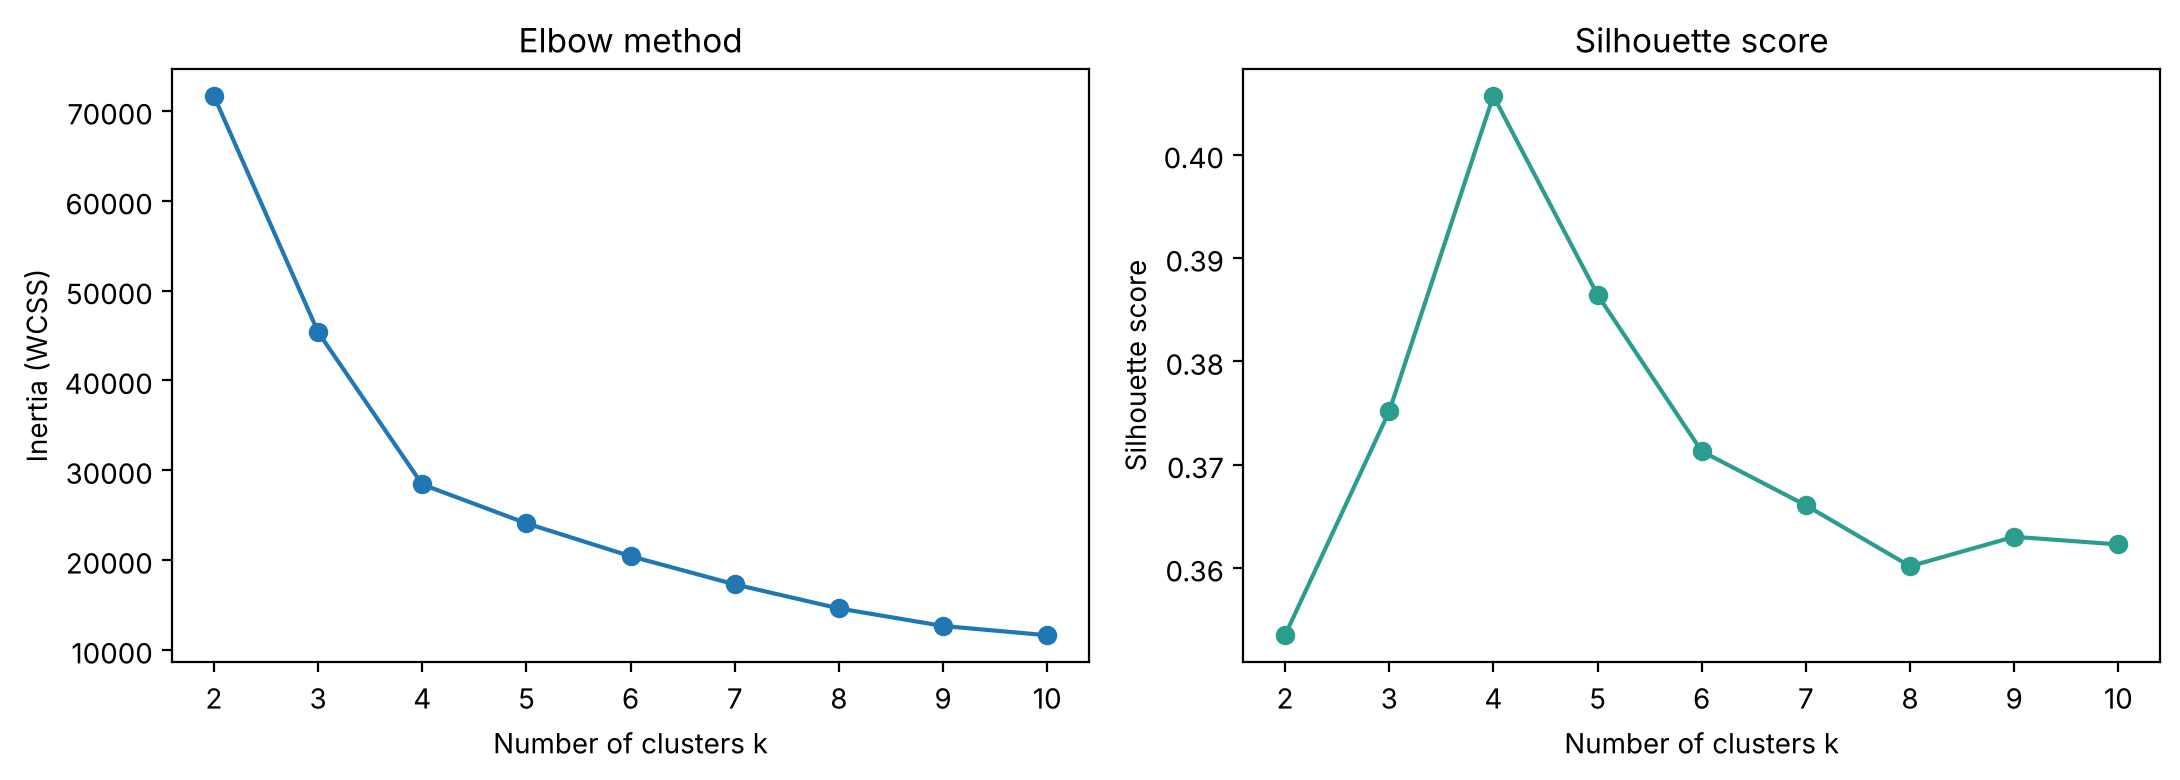

In [25]:
clu = data[['age', 'days_to_recovery']].copy()
clu_s = StandardScaler().fit_transform(clu)
sil_sample = np.random.RandomState(RANDOM_STATE).choice(len(clu_s), 10000, replace=False)

inertia, sil = [], []
k_range = range(2, 11)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(clu_s)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(clu_s[sil_sample], km.labels_[sil_sample]))
k_table = pd.DataFrame({'k': list(k_range), 'Inertia (WCSS)': np.round(inertia, 0), 'Silhouette': np.round(sil, 4)})
print(k_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(list(k_range), inertia, 'o-'); axes[0].set_xlabel('Number of clusters k'); axes[0].set_ylabel('Inertia (WCSS)'); axes[0].set_title('Elbow method')
axes[1].plot(list(k_range), sil, 'o-', color='#2a9d8f'); axes[1].set_xlabel('Number of clusters k'); axes[1].set_ylabel('Silhouette score'); axes[1].set_title('Silhouette score')
plt.tight_layout(); plt.savefig('figures/clu_elbow.png', dpi=150); plt.show()

In [26]:
K = 4   # elbow bends at 4 and silhouette stays near its best; 4 groups map onto young/old x short/long recovery
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(clu_s)
data['kmeans_cluster'] = kmeans.labels_
print('K-means silhouette (k=4):', round(silhouette_score(clu_s[sil_sample], kmeans.labels_[sil_sample]), 4))

K-means silhouette (k=4): 0.4057


###### 8.2 Hierarchical (Ward) clustering on a 3,000-row random sample (the full linkage matrix would need ~13 GB of memory)

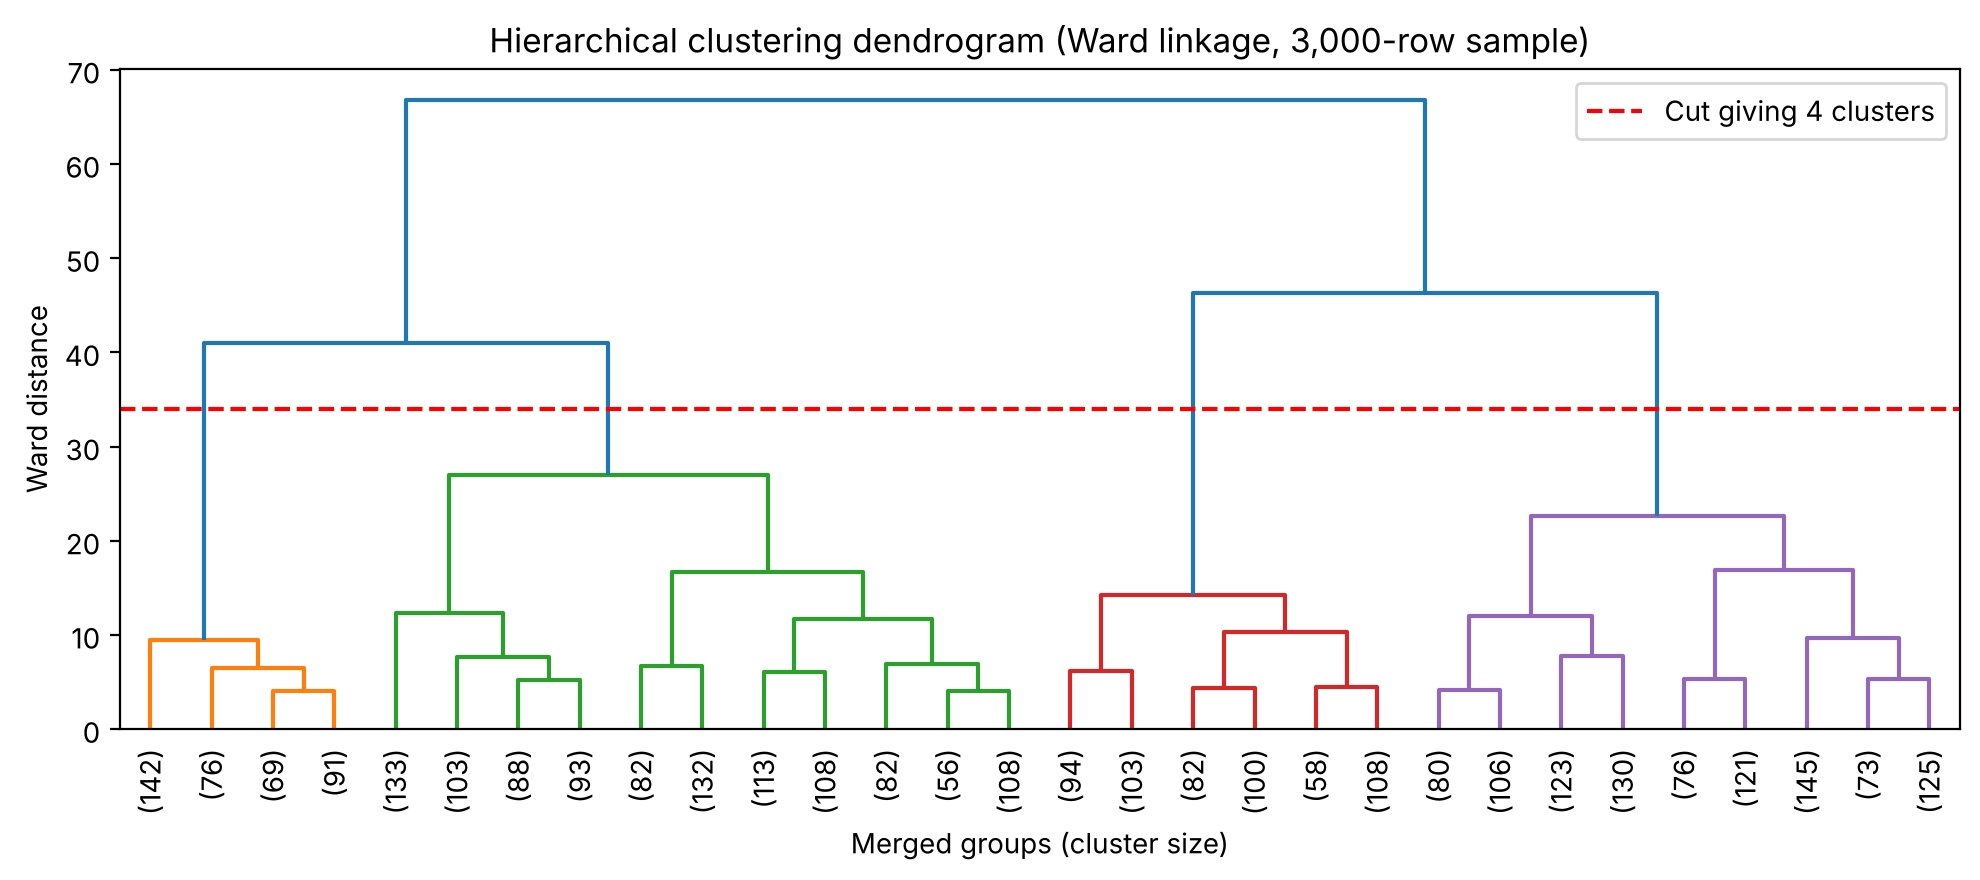

Hierarchical silhouette (k=4, sample): 0.3342
Agreement with K-means on the same rows (Adjusted Rand Index): 0.5852


In [27]:
h_idx = np.random.RandomState(RANDOM_STATE).choice(len(clu_s), 3000, replace=False)
Z = linkage(clu_s[h_idx], method='ward')
cut = (Z[-K, 2] + Z[-K + 1, 2]) / 2      # midway between the merges that give K and K-1 clusters
plt.figure(figsize=(10, 4.5))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90, color_threshold=cut)
plt.axhline(cut, color='red', ls='--', label=f'Cut giving {K} clusters')
plt.title('Hierarchical clustering dendrogram (Ward linkage, 3,000-row sample)')
plt.xlabel('Merged groups (cluster size)'); plt.ylabel('Ward distance'); plt.legend()
plt.tight_layout(); plt.savefig('figures/clu_dendrogram.png', dpi=150); plt.show()

hier = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(clu_s[h_idx])
print('Hierarchical silhouette (k=4, sample):', round(silhouette_score(clu_s[h_idx], hier.labels_), 4))
print('Agreement with K-means on the same rows (Adjusted Rand Index):',
      round(adjusted_rand_score(kmeans.labels_[h_idx], hier.labels_), 4))

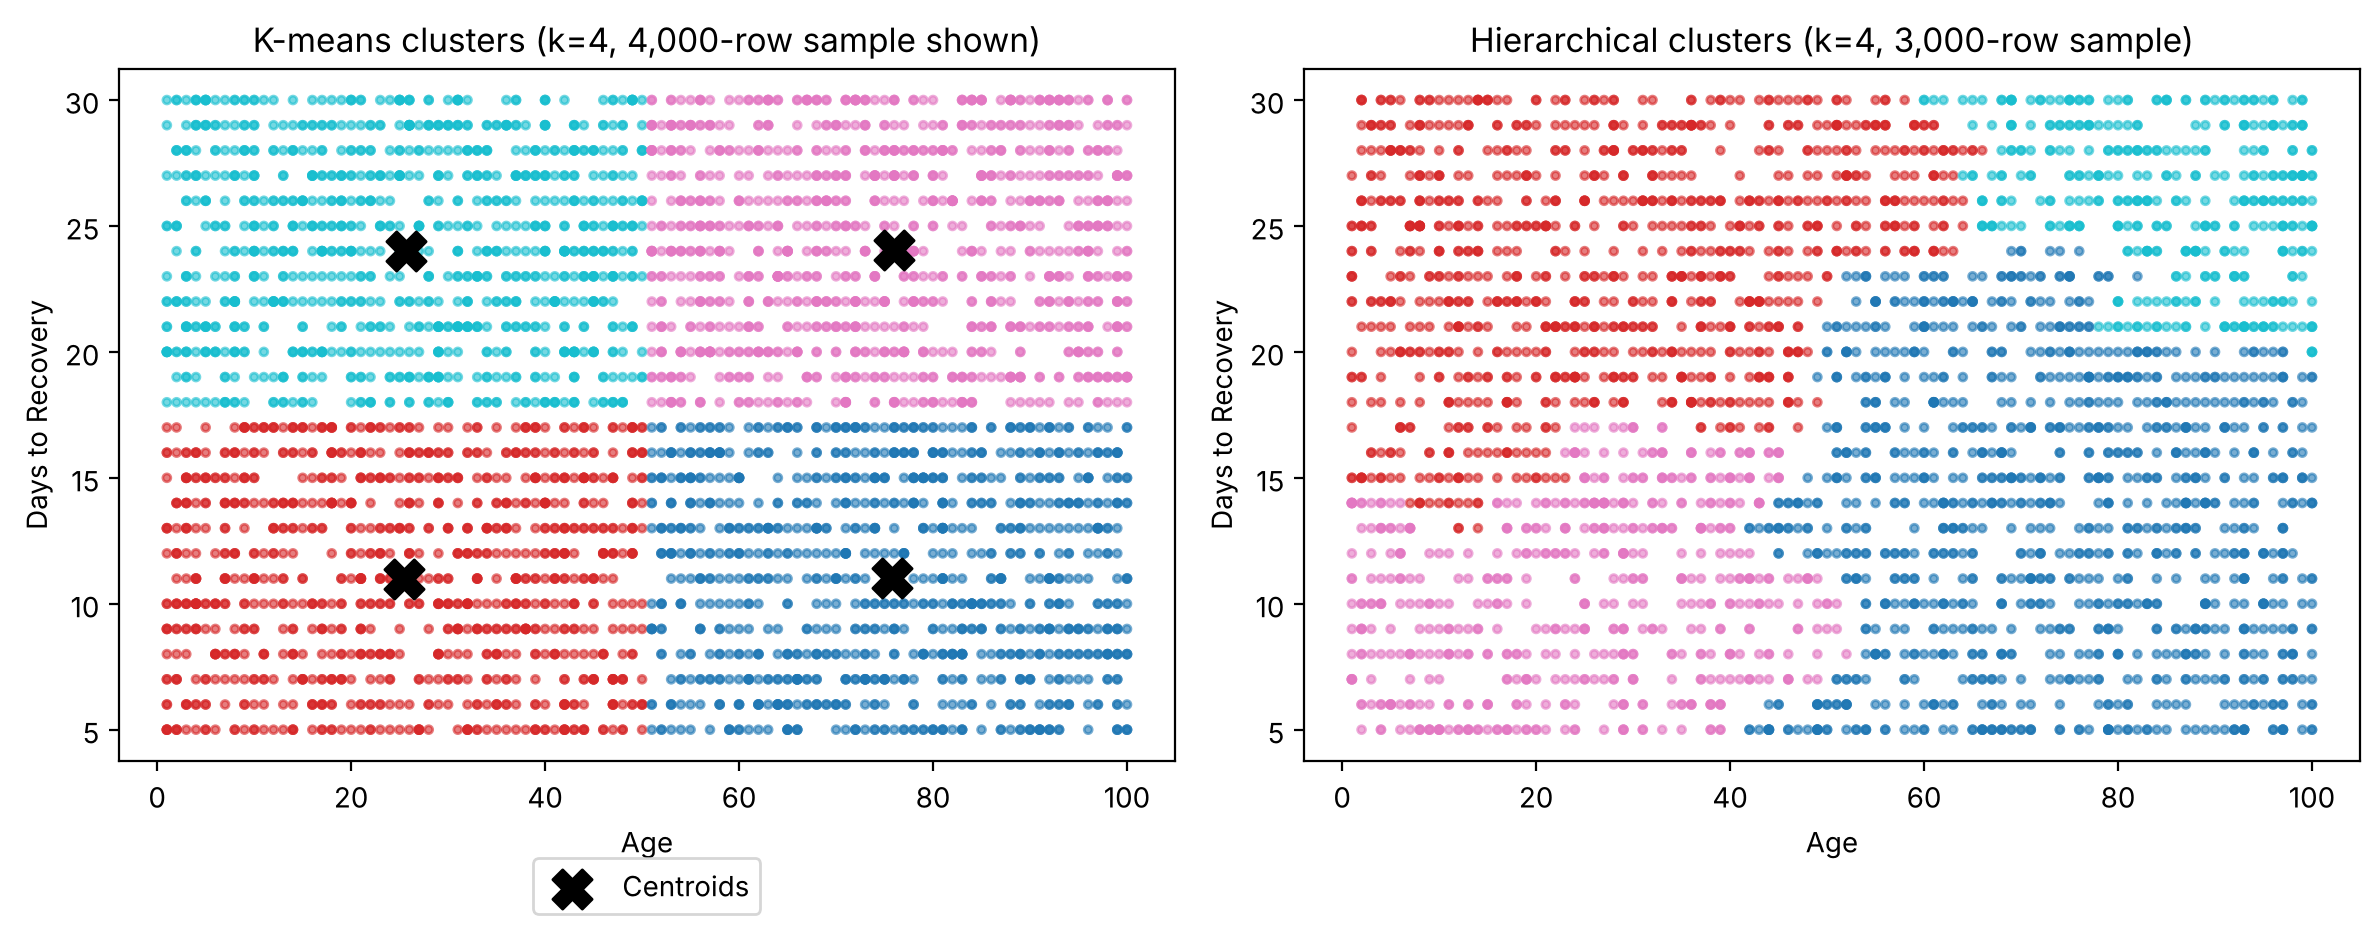

In [28]:
centres = pd.DataFrame(StandardScaler().fit(clu).inverse_transform(kmeans.cluster_centers_), columns=['age', 'days_to_recovery'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
plot_idx = np.random.RandomState(1).choice(len(clu), 4000, replace=False)
axes[0].scatter(clu.iloc[plot_idx]['age'], clu.iloc[plot_idx]['days_to_recovery'], c=kmeans.labels_[plot_idx], cmap='tab10', s=8, alpha=0.6)
axes[0].scatter(centres['age'], centres['days_to_recovery'], c='black', marker='X', s=200, label='Centroids')
axes[0].set_title('K-means clusters (k=4, 4,000-row sample shown)'); axes[0].set_xlabel('Age'); axes[0].set_ylabel('Days to Recovery'); axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12))
axes[1].scatter(clu.iloc[h_idx]['age'], clu.iloc[h_idx]['days_to_recovery'], c=hier.labels_, cmap='tab10', s=8, alpha=0.6)
axes[1].set_title('Hierarchical clusters (k=4, 3,000-row sample)'); axes[1].set_xlabel('Age'); axes[1].set_ylabel('Days to Recovery')
plt.tight_layout(); plt.savefig('figures/clu_scatter.png', dpi=150); plt.show()

###### 8.3 Cluster profiles

In [29]:
profile_src = df_clean.loc[data.index].assign(cluster=data['kmeans_cluster'])
profile = profile_src.groupby('cluster').agg(
    patients=('age', 'size'), mean_age=('age', 'mean'), min_age=('age', 'min'), max_age=('age', 'max'),
    mean_days=('days_to_recovery', 'mean'), min_days=('days_to_recovery', 'min'), max_days=('days_to_recovery', 'max'),
    pct_severe_or_critical=('severity', lambda s: s.isin(['Severe', 'Critical']).mean() * 100),
    pct_with_comorbidity=('comorbidities', lambda s: s.notna().mean() * 100),
    pct_vaccinated=('vaccination_status', lambda s: s.notna().mean() * 100),
    death_rate=('death', lambda s: s.mean() * 100)).round(1)
profile

,patients,mean_age,min_age,max_age,mean_days,min_days,max_days,pct_severe_or_critical,pct_with_comorbidity,pct_vaccinated,death_rate
cluster,,,,,,,,,,,
0,14571,75.8,51,100,11.0,5,17,15.6,83.9,60.2,64.8
1,14054,25.5,1,50,11.0,5,17,15.9,82.9,58.8,77.7
2,14614,75.8,51,100,24.0,18,30,16.0,83.6,58.5,65.4
3,14275,25.5,1,50,24.0,18,30,16.6,83.5,60.2,77.4
